# Bat Speed Normative Model: Is It Worth Building?

A risk-adjusted chart would compare each swing with what *this player* should produce in *these conditions*
(count, pitch type and speed, location, platoon, park, home/away), and monitor the residuals.
That only helps if the conditions explain a meaningful share of a player's game-to-game bat-speed variation.
This notebook measures that share on healthy league swings from 2024–2026.

**Rough guide:** under ~5% of game-level variance explained, residual charts would look like the raw charts;
~15% or more, they are worth building.

## 0. Setup

In [1]:
%pip install -q pybaseball requests pandas numpy openpyxl matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import oblique_study as study
import normative_model as nm

from pybaseball import cache
cache.enable()

## 1. Cohort and full injury table

The full injury table (every IL stint for every player) is used to drop swings during or within 30 days after any IL stint,
so the norm describes healthy hitters. The oblique cohort's own player-seasons are excluded from the league sample.

In [3]:
injuries = study.load_all_injuries()
cohort = study.select_oblique_batters(injuries)
print(len(cohort), "cohort player-seasons;", len(injuries), "player-seasons with any IL stint")

157 cohort player-seasons; 4170 player-seasons with any IL stint


## 2. Sample league swings

60 random hitters with 200+ PA per season, 2024–2026, pulled one player-season at a time (about 2,000 pitches each, so memory stays small).
Only bat-tracked, non-bunt swings in regular-season games are kept, and the slowest 10% of each player-season's swings are dropped
unless the ball was hit 90+ mph (an approximation of Savant's "competitive swings").

First run: about 180 requests, roughly 15–30 minutes. Results are cached in `data/statcast_swings/`.

In [4]:
# Quick test on 3 hitters before the full pull
test = nm.sample_league_swings(cohort, injuries, seasons=[2025], n_per_season=3)
print(len(test), "swings")
test.head()

Gathering player lookup table. This may take a moment.
0 sampled hitters had no MLBAM match and were skipped
Gathering Player Data
Gathering Player Data
Gathering Player Data
2428 swings


,game_pk,game_date,batter,at_bat_number,pitch_number,description,bat_speed,swing_length,launch_speed,balls,...,release_speed,plate_x,plate_z,sz_top,sz_bot,stand,p_throws,inning_topbot,home_team,season
0,776148,2025-09-28,596019,39,5,foul,74.1,7.7,81.8,2,...,86.2,-0.246226,1.345076,3.43,1.6,L,R,Top,MIA,2025
1,776148,2025-09-28,596019,74,2,hit_into_play,83.9,7.8,105.6,0,...,85.8,-0.122291,2.056410,3.43,1.6,L,R,Top,MIA,2025
2,776148,2025-09-28,596019,1,4,swinging_strike,71.7,8.5,NaN,1,...,86.0,0.292589,1.334497,3.43,1.6,L,R,Top,MIA,2025
3,776148,2025-09-28,596019,1,2,foul,74.8,7.5,94.3,1,...,98.6,-0.532974,2.338069,3.43,1.6,L,R,Top,MIA,2025
4,776161,2025-09-27,596019,33,8,swinging_strike,65.4,8.3,NaN,3,...,86.4,0.901303,1.157090,3.45,1.6,L,R,Top,MIA,2025


In [5]:
swings = nm.sample_league_swings(cohort, injuries)
print(f"{len(swings):,} healthy competitive swings from "
      f"{swings.groupby(['batter', 'season']).ngroups} player-seasons")

5 sampled hitters had no MLBAM match and were skipped
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
  25/175 player-seasons
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Dat

## 3. How much do the conditions explain?

Bat speed and each covariate are centered within player-season, so the model only explains variation *around each hitter's own level*.
Effects are estimated on half the player-seasons and evaluated on the other half (and vice versa).

The **game-level** number is the one that matters for the chart, which works on game averages.

In [6]:
summary, coefs, games = nm.variance_explained_check(swings)
pd.Series(summary).round(3)

player_seasons                 147.000
swings                      100110.000
games                        14619.000
swing_sd_within                  3.907
swing_sd_adjusted                3.598
swing_variance_explained         0.152
game_sd_raw                      1.839
game_sd_adjusted                 1.719
game_variance_explained          0.126
dtype: float64

In [7]:
# Estimated effects (mph), excluding the park dummies
coefs[[c for c in coefs.index if not c.startswith("park_")]].round(2)

count_0-1         -0.56
count_0-2         -1.67
count_1-0          0.40
count_1-1         -0.29
count_1-2         -1.38
count_2-0          1.03
count_2-1          0.25
count_2-2         -1.08
count_3-0          1.60
count_3-1          1.10
count_3-2         -0.53
pitch_breaking    -0.11
pitch_cutter       0.10
pitch_offspeed     0.27
pitch_other       -0.58
velo              -0.05
velo_x_breaking    0.10
velo_x_offspeed    0.11
velo_x_cutter      0.03
loc_in             0.94
loc_in2           -1.39
loc_z             -2.19
loc_z2            -3.52
loc_in_z          -0.62
same_hand         -0.44
home               0.08
dtype: float64

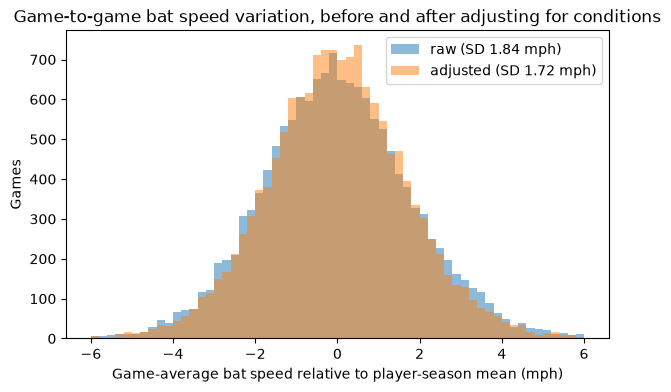

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(-6, 6, 61)
ax.hist(games["raw"], bins=bins, alpha=0.5, label=f"raw (SD {games['raw'].std():.2f} mph)")
ax.hist(games["adjusted"], bins=bins, alpha=0.5, label=f"adjusted (SD {games['adjusted'].std():.2f} mph)")
ax.set(xlabel="Game-average bat speed relative to player-season mean (mph)", ylabel="Games",
       title="Game-to-game bat speed variation, before and after adjusting for conditions")
ax.legend()
plt.show()

## 4. Reading the result

- `game_variance_explained` is the share of game-to-game variance the conditions remove.
  The residual chart's noise SD would be `game_sd_adjusted` instead of `game_sd_raw`.
- A shift the chart must detect (e.g., the ~0.7 mph gap seen among reinjured players) becomes easier to detect in proportion to
  `game_sd_raw / game_sd_adjusted`.

In [9]:
ratio = summary["game_sd_raw"] / summary["game_sd_adjusted"]
print(f"Noise reduction: {1 - 1/ratio:.1%} smaller SD")
print(f"A 0.7 mph shift is {0.7 / summary['game_sd_raw']:.2f} SD raw "
      f"vs {0.7 / summary['game_sd_adjusted']:.2f} SD after adjustment")

Noise reduction: 6.5% smaller SD
A 0.7 mph shift is 0.38 SD raw vs 0.41 SD after adjustment
